# URL Classifier v4: fixing the train/serve gap

The v3 model scores 91.94% on its test split but flags `https://www.wikipedia.org/` as malicious.
The cause is in the data, not the model: in `malicious_phish.csv`, URL *formatting* (scheme, `www.`,
bare homepages) is almost a label by itself, and every URL a browser sends looks like the malicious side.

Each step below is measured against the **same** held-out sets so its effect is visible on its own:

1. Clean the Kaggle data: drop defacement, dedupe, remove label conflicts
2. Add modern data on **both** sides - benign: Tranco homepages, Hacker News pages;
   malicious: PhishTank, URLhaus - plus OpenPhish as a never-trained-on test set
3. One host-grouped split, so no site is in both training and test
4. **B** normalize URLs, **C** + Tranco homepages, **D** + v4 features (Kaggle-era data only)
5. **E** + the modern benign and malicious data, **F** a character n-gram model, **G** E and F averaged
6. A popularity allowlist in front of the model
7. Pick the model and threshold for a 2.5% false-positive rate on real pages, then save

An earlier run of this notebook added modern *benign* data only. The n-gram model then learned
"looks like 2026 = benign" (its top benign n-grams were `2026`, `.io`, `.ai`) and caught 3% of live
phishing. Both classes now get modern data, and digits are masked for the n-gram model.

In [1]:
import io
import os
import json
import datetime
import zipfile
import gc
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score

from features import (normalize_url, extract_features, extract_features_v3, text_for_ngrams,
                      FEATURE_COLUMNS, FEATURE_COLUMNS_V3)
import allowlist as allowlist_module

RANDOM_STATE = 42

# Where the model, allowlist and metrics are written. retrain.py points this at a candidate folder
# so a run can be checked before it replaces the live model; run by hand, it's the project root.
OUTPUT_DIR = os.environ.get('THREATSCANNER_OUTPUT_DIR', '.')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Same settings v3's RandomizedSearchCV picked, so differences come from the data and features.
# class_weight='balanced' because the models trained on subsets of the pool are imbalanced.
RF_PARAMS = dict(n_estimators=200, min_samples_split=5, min_samples_leaf=1, max_depth=None,
                 class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)

# A shortened link says nothing about its destination, and in the browser the extension sees the
# page it redirects to anyway - so shortener URLs are left out of training and evaluation
SHORTENERS = ('bit.ly', 'tinyurl.com', 't.co', 'is.gd', 'goo.gl', 'ow.ly', 'buff.ly', 'rebrand.ly',
              'cutt.ly', 'shorturl.at', 'qrco.de', 'q-r.to', 'l.ead.me', 'rb.gy', 's.id', 'tiny.cc',
              'lnkd.in', 'linktr.ee', 'forms.gle', 't.ly', 'v.gd', 'shorturl.ac', 'qr.link')

def host_of(url):
    # Hostname of the normalized URL (no port, credentials or www.) - the unit we group splits by
    try:
        return urllib.parse.urlparse('http://' + normalize_url(url)).hostname or ''
    except ValueError:
        return ''

def is_shortener(hostname):
    return any(hostname == s or hostname.endswith('.' + s) for s in SHORTENERS)

def cap_per_host(frame, k):
    # A handful of hosts (github.com, docs.google.com) have thousands of rows; capping keeps
    # any one site from dominating training or a score
    return frame.sample(frac=1, random_state=RANDOM_STATE).groupby('host').head(k)

## Step 1: The formatting leak, and cleaning the Kaggle data

In [2]:
raw = pd.read_csv('malicious_phish.csv')
u = raw['url'].astype(str)
raw['scheme'] = u.str.extract(r'^(https?)://', expand=False).fillna('none')
raw['starts_www'] = u.str.replace(r'^https?://', '', regex=True).str.startswith('www.')

# How each class is *formatted* - a browser URL is always https://www.-style
print("Scheme share per class:")
print(pd.crosstab(raw['type'], raw['scheme'], normalize='index').round(3))
print("\nShare starting with www. (after any scheme):")
print(raw.groupby('type')['starts_www'].mean().round(3))

Scheme share per class:
scheme       http  https   none
type                           
benign      0.078  0.005  0.917
defacement  1.000  0.000  0.000
malware     0.755  0.208  0.037
phishing    0.190  0.074  0.736

Share starting with www. (after any scheme):


type
benign        0.031
defacement    0.698
malware       0.093
phishing      0.387
Name: starts_www, dtype: float64


In [3]:
# Defacement URLs are legitimate sites that were hacked (mostly Joomla-style query strings);
# they're not what a phishing/malware blocker targets and they teach "CMS URL = malicious"
df = raw[raw['type'] != 'defacement'][['url', 'type']].copy()
df['label'] = (df['type'] != 'benign').astype(int)

df['norm_url'] = df['url'].map(normalize_url)
df['host'] = df['url'].map(host_of)

before = len(df)
# Normalization makes e.g. "http://www.a.com/" and "a.com" the same URL; a URL carrying
# both labels is noise, so those are dropped entirely rather than picking one
label_counts = df.groupby('norm_url')['label'].nunique()
conflicting = label_counts[label_counts > 1].index
df = df[~df['norm_url'].isin(conflicting)].drop_duplicates('norm_url')
df = df[(df['host'] != '') & ~df['host'].map(is_shortener)]

print(f"Rows after dropping defacement: {before}")
print(f"Conflicting normalized URLs dropped: {len(conflicting)}")
print(f"Rows after dedupe: {len(df)}")
print(df['type'].value_counts())

Rows after dropping defacement: 554734
Conflicting normalized URLs dropped: 4026
Rows after dedupe: 532984
type
benign      422052
phishing     87341
malware      23591
Name: count, dtype: int64


## Step 2: Modern data for both classes

| Source | Class | What it is |
|---|---|---|
| Tranco top 100k | benign | Popular domains, as homepages. 10k train, 5k held out (sent as `https://www.<domain>/`) |
| Hacker News | benign | Upvoted (points >= 3) story links, Jan-Oct 2026: real inner pages on ~25k sites |
| PhishTank | malicious | Community-verified phishing, mostly 2023-2026 |
| URLhaus | malicious | Malware distribution URLs, 2018-2026 |
| OpenPhish | malicious | Live phishing feed - **test only**, its hosts are excluded from everything else |

In [4]:
with zipfile.ZipFile('data/external/tranco.zip') as z:
    tranco_full = pd.read_csv(z.open('top-1m.csv'), header=None, names=['rank', 'domain'])

# One URL per line; read as text since URLs can contain commas
with open('data/external/openphish.txt', encoding='utf-8') as f:
    openphish = pd.DataFrame({'url': [line.strip() for line in f if line.strip()]})

# URLhaus prefixes its CSVs with '#' comment lines; pandas' comment= option would also cut
# URLs containing '#', so the header block is skipped by hand instead
URLHAUS_COLUMNS = ['id', 'dateadded', 'url', 'url_status', 'last_online', 'threat', 'tags',
                   'urlhaus_link', 'reporter']
def read_urlhaus(text_lines):
    body = ''.join(line for line in text_lines if not line.startswith('#'))
    return pd.read_csv(io.StringIO(body), header=None, quotechar='"', names=URLHAUS_COLUMNS)

with zipfile.ZipFile('data/external/urlhaus_full.zip') as z:
    urlhaus_full = read_urlhaus(io.TextIOWrapper(z.open('csv.txt'), encoding='utf-8'))
with open('data/external/urlhaus_recent.csv', encoding='utf-8') as f:
    urlhaus_recent = read_urlhaus(f)
urlhaus = pd.concat([urlhaus_full, urlhaus_recent])[['url']]

phishtank = pd.read_csv('data/external/phishtank.csv')[['url']]
hn = pd.read_csv('data/external/hn_urls.csv')[['url']]

def prepare(frame, source, label, cap):
    frame = frame[['url']].copy()
    frame['host'] = frame['url'].map(host_of)
    frame = frame[(frame['host'] != '') & ~frame['host'].map(is_shortener)]
    frame = frame.assign(norm_url=frame['url'].map(normalize_url)).drop_duplicates('norm_url')
    frame = cap_per_host(frame, cap)
    return frame.assign(source=source, label=label)

openphish_eval = prepare(openphish, 'openphish', 1, cap=1)
openphish_hosts = set(openphish_eval['host'])

phishtank_rows = prepare(phishtank, 'phishtank', 1, cap=20)
urlhaus_rows = prepare(urlhaus, 'urlhaus', 1, cap=5)
hn_rows = prepare(hn, 'hn', 0, cap=30)

# Top 100k only - deeper in the list, more low-quality and malicious domains appear
tranco = tranco_full[tranco_full['rank'] <= 100_000].rename(columns={'domain': 'url'})
tranco = prepare(tranco, 'tranco', 0, cap=1).sample(frac=1, random_state=RANDOM_STATE)

for name, frame in [('PhishTank', phishtank_rows), ('URLhaus', urlhaus_rows), ('Hacker News', hn_rows),
                    ('Tranco', tranco), ('OpenPhish (test only)', openphish_eval)]:
    print(f"{name:22} rows={len(frame):7}  hosts={frame['host'].nunique():6}")

PhishTank              rows=  33306  hosts= 29194
URLhaus                rows=  33448  hosts= 17780
Hacker News            rows=  70425  hosts= 36544
Tranco                 rows=  99981  hosts= 99981
OpenPhish (test only)  rows=    280  hosts=   280


## Step 3: Balanced pool and a host-grouped split

v3 split rows at random, so the same host (e.g. `en.wikipedia.org` has 13k rows) landed in both
train and test and the score partly measured memorization. Here every host lives on exactly one
side of the split. All models share this split; the earlier ones just use fewer of its sources.

In [5]:
# Hosts in the Kaggle data are kept out of the Tranco homepage sets, which would only
# duplicate (or contradict) Kaggle's labels
kaggle_hosts = set(df['host'])
tranco = tranco[~tranco['host'].isin(kaggle_hosts)]
tranco_eval, tranco_train = tranco.iloc[:5_000], tranco.iloc[5_000:15_000]

kaggle_malicious = df[df['label'] == 1].assign(source='kaggle')
modern_malicious = pd.concat([phishtank_rows, urlhaus_rows])
n_malicious = len(kaggle_malicious) + len(modern_malicious)

n_kaggle_benign = n_malicious - len(tranco_train) - len(hn_rows)
kaggle_benign = df[df['label'] == 0].sample(n=n_kaggle_benign, random_state=RANDOM_STATE).assign(source='kaggle')

pool = pd.concat([kaggle_malicious, kaggle_benign, modern_malicious, hn_rows, tranco_train],
                 ignore_index=True)[['url', 'label', 'host', 'source']]
# OpenPhish must stay unseen; held-out Tranco homepages must not appear as training rows
pool = pool[~pool['host'].isin(openphish_hosts | set(tranco_eval['host']))].reset_index(drop=True)

# 20% test, then 12.5% of the rest (10% overall) as validation for picking the threshold
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(outer.split(pool, groups=pool['host']))
trainval, test = pool.iloc[trainval_idx], pool.iloc[test_idx]

inner = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=RANDOM_STATE)
train_idx, val_idx = next(inner.split(trainval, groups=trainval['host']))
train, val = trainval.iloc[train_idx], trainval.iloc[val_idx]

assert not set(train['host']) & set(test['host']), "host leaked between train and test"
assert not set(pool['host']) & openphish_hosts, "OpenPhish host leaked into the pool"
print(f"Malicious share of pool: {pool['label'].mean():.3f}")
print(pd.crosstab(pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test')])['split'],
                  pd.concat([train, val, test])['source']))

Malicious share of pool: 0.501
source     hn  kaggle  phishtank  tranco  urlhaus
split                                            
test    13737   40841       6546    2000     6509
train   48974  147360      23343    7003    23630
val      7149   19992       3288     997     3308


## Step 4: Evaluation harness

Every model is scored on the same sets. For a blocking extension the most important number is the
**false-positive rate on real browsing** (`browsing_fpr` = 80% `hn_fpr` inner pages + 20% `homepage_fpr`):
every false positive is a page the user can't open.
The catch rates that matter most are on live phishing (`phishtank_tpr`, `openphish_tpr`).

In [6]:
# Real browsing sends full URLs, so the held-out homepages go in browser form
test_kaggle = test[test['source'] == 'kaggle']
EVAL_SETS = {
    'test': test_kaggle['url'].tolist(),
    'homepages': ('https://www.' + tranco_eval['url'] + '/').tolist(),
    # 5 per host so a few big sites don't decide the score
    'hn': cap_per_host(test[test['source'] == 'hn'], 5)['url'].tolist(),
    'phishtank': cap_per_host(test[test['source'] == 'phishtank'], 5)['url'].tolist(),
    'urlhaus': test[test['source'] == 'urlhaus']['url'].tolist(),
    'openphish': openphish_eval['url'].tolist(),
}
y_test = test_kaggle['label'].to_numpy()
for name, urls in EVAL_SETS.items():
    print(f"{name:10} {len(urls):6} URLs")

# Everyday browsing is mostly inner pages with some homepages; this blend is the
# false-positive rate the threshold is tuned for
BROWSING_MIX = {'hn': 0.8, 'homepages': 0.2}

def featurize(urls, extractor, columns):
    return pd.DataFrame([extractor(u) for u in urls])[columns]

def score_sets(predict_proba):
    # Scores every eval set once; metrics at any threshold are then cheap
    return {name: predict_proba(urls) for name, urls in EVAL_SETS.items()}

def metrics(name, scores, threshold=0.5):
    t = scores['test']
    hn_fpr = (scores['hn'] > threshold).mean()
    homepage_fpr = (scores['homepages'] > threshold).mean()
    return {
        'model': name,
        'test_auc': roc_auc_score(y_test, t),
        'test_fpr': (t[y_test == 0] > threshold).mean(),
        'test_tpr': (t[y_test == 1] > threshold).mean(),
        'homepage_fpr': homepage_fpr,
        'hn_fpr': hn_fpr,
        'browsing_fpr': BROWSING_MIX['hn'] * hn_fpr + BROWSING_MIX['homepages'] * homepage_fpr,
        'phishtank_tpr': (scores['phishtank'] > threshold).mean(),
        'openphish_tpr': (scores['openphish'] > threshold).mean(),
        'urlhaus_tpr': (scores['urlhaus'] > threshold).mean(),
    }

scores, results = {}, []
def record(name, predict_proba):
    scores[name] = score_sets(predict_proba)
    results.append(metrics(name, scores[name]))
    print(pd.DataFrame(results).set_index('model').round(4).to_string())

test        40841 URLs
homepages    5000 URLs
hn          10908 URLs
phishtank    6229 URLs
urlhaus      6509 URLs
openphish     280 URLs


### Baseline: the current v3 model

Caveat in v3's favor: it was trained on a random split of the full Kaggle data, so many of the
Kaggle test hosts (and URLs) were in its training set. Its `test_*` numbers are optimistic; the
other sets are a fair comparison.

In [7]:
# The v3 baseline is only for comparison; a fresh clone without it can still train v4
if os.path.exists('url_classifier_v3.joblib'):
    v3_model = joblib.load('url_classifier_v3.joblib')
    record('v3 (current)', lambda urls: v3_model.predict_proba(featurize(urls, extract_features_v3, FEATURE_COLUMNS_V3))[:, 1])
    del v3_model
    gc.collect()
else:
    print("url_classifier_v3.joblib not found - skipping the v3 baseline")

              test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                    
v3 (current)    0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438


48

### B, C, D: Kaggle-era data only

* **B** - normalized URLs with the v3 features
* **C** - + 10k Tranco benign homepages
* **D** - + the v4 features (`features.py`: token keywords, brand impersonation such as
  `paypal.com.evil.xyz`, query and host metrics, ports, `user@host`)

In [8]:
v3_on_normalized = lambda u: extract_features_v3(normalize_url(u))

def train_rf(rows, extractor, columns):
    model = RandomForestClassifier(**RF_PARAMS)
    model.fit(featurize(rows['url'], extractor, columns), rows['label'])
    return model

for name, sources, extractor, columns in [
        ('B: normalized', ['kaggle'], v3_on_normalized, FEATURE_COLUMNS_V3),
        ('C: + Tranco', ['kaggle', 'tranco'], v3_on_normalized, FEATURE_COLUMNS_V3),
        ('D: + v4 features', ['kaggle', 'tranco'], extract_features, FEATURE_COLUMNS)]:
    model = train_rf(train[train['source'].isin(sources)], extractor, columns)
    record(name, lambda urls: model.predict_proba(featurize(urls, extractor, columns))[:, 1])
    del model
    gc.collect()

               test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                     
v3 (current)     0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized    0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614


               test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                     
v3 (current)     0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized    0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco      0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624


                  test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                        
v3 (current)        0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized       0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco         0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624
D: + v4 features    0.8240    0.2431    0.7336        0.2392  0.2625        0.2578         0.7203         0.9214       0.9630


### E: + modern benign and malicious data

In [9]:
model_e = train_rf(train, extract_features, FEATURE_COLUMNS)
proba_e = lambda urls: model_e.predict_proba(featurize(urls, extract_features, FEATURE_COLUMNS))[:, 1]
record('E: + modern data', proba_e)

                  test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                        
v3 (current)        0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized       0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco         0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624
D: + v4 features    0.8240    0.2431    0.7336        0.2392  0.2625        0.2578         0.7203         0.9214       0.9630
E: + modern data    0.8079    0.2195    0.6581        0.1660  0.1721        0.1709         0.8743         0.9321       0.9616


### F: character n-gram model

Instead of 21 hand-built measurements, TF-IDF over every 3-5 character sequence of the normalized
URL (digits masked as `0`, see `text_for_ngrams`) lets a linear model learn which fragments matter.
The regularization strength is picked on the validation split.

In [10]:
vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=500_000,
                             sublinear_tf=True, dtype=np.float32)
X_train_text = vectorizer.fit_transform(train['url'].map(text_for_ngrams))
X_val_text = vectorizer.transform(val['url'].map(text_for_ngrams))
print(f"Vocabulary: {len(vectorizer.vocabulary_)} n-grams")

best = None
for C in [1, 4, 16]:
    lr = LogisticRegression(C=C, max_iter=2000, solver='liblinear', class_weight='balanced')
    lr.fit(X_train_text, train['label'])
    auc = roc_auc_score(val['label'], lr.predict_proba(X_val_text)[:, 1])
    print(f"C={C:<3} validation AUC={auc:.4f}")
    if best is None or auc > best[0]:
        best = (auc, C, lr)
_, best_C, model_f = best
print(f"Using C={best_C}")

proba_f = lambda urls: model_f.predict_proba(vectorizer.transform([text_for_ngrams(u) for u in urls]))[:, 1]
record('F: char n-grams', proba_f)

Vocabulary: 500000 n-grams


C=1   validation AUC=0.9459


C=4   validation AUC=0.9460


C=16  validation AUC=0.9402
Using C=4


                  test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                        
v3 (current)        0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized       0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco         0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624
D: + v4 features    0.8240    0.2431    0.7336        0.2392  0.2625        0.2578         0.7203         0.9214       0.9630
E: + modern data    0.8079    0.2195    0.6581        0.1660  0.1721        0.1709         0.8743         0.9321       0.9616
F: char n-grams     0.9379    0.1167    0.8411        0.3334  0.0879        0.1370         0.9395         0.9500      

### G: E and F averaged

The two models look at URLs differently (structure vs. text fragments), so their mistakes
should only partly overlap.

In [11]:
proba_g = lambda urls: (proba_e(urls) + proba_f(urls)) / 2
scores['G: E + F'] = {k: (scores['E: + modern data'][k] + scores['F: char n-grams'][k]) / 2 for k in EVAL_SETS}
results.append(metrics('G: E + F', scores['G: E + F']))
comparison = pd.DataFrame(results).set_index('model')
print(comparison.round(4).to_string())

                  test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                        
v3 (current)        0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized       0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco         0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624
D: + v4 features    0.8240    0.2431    0.7336        0.2392  0.2625        0.2578         0.7203         0.9214       0.9630
E: + modern data    0.8079    0.2195    0.6581        0.1660  0.1721        0.1709         0.8743         0.9321       0.9616
F: char n-grams     0.9379    0.1167    0.8411        0.3334  0.0879        0.1370         0.9395         0.9500      

## Step 5: Popularity allowlist

The Tranco top 10k domains are treated as Safe before the model runs, except platforms where anyone
can publish under the platform's domain (`blogspot.com`, `pages.dev`, `docs.google.com`, shorteners...;
see `PLATFORM_SUFFIXES` in `allowlist.py`). This is how production URL filters work: a lexical model
for the long tail, reputation for the head.

In [12]:
ALLOWLIST_SIZE = 10_000
second_level = {'co', 'com', 'net', 'org', 'gov', 'ac', 'edu'}
top = tranco_full[tranco_full['rank'] <= ALLOWLIST_SIZE]['domain'].str.lower()
# Bare public suffixes (co.uk, com.au) would allowlist entire countries
top = top[~top.map(lambda d: len(d.split('.')) == 2 and d.split('.')[0] in second_level)]
top = top[~top.map(allowlist_module.is_platform)]
allow_set = frozenset(top)

with open(os.path.join(OUTPUT_DIR, 'allowlist.txt'), 'w', encoding='utf-8') as f:
    f.write(f"# Tranco top {ALLOWLIST_SIZE} (https://tranco-list.eu), minus user-content platforms.\n")
    f.write("# Generated by url_model_v4.ipynb - do not edit by hand.\n")
    f.write('\n'.join(sorted(allow_set)) + '\n')
print(f"Allowlist: {len(allow_set)} domains written to allowlist.txt")

allowed = {name: np.array([allowlist_module.is_allowlisted(u, allow_set) for u in urls])
           for name, urls in EVAL_SETS.items()}
for name, mask in allowed.items():
    print(f"{name:10} allowlisted: {mask.mean():.1%}")

# Malicious URLs the allowlist would wave through - worth knowing what they are
malicious_masks = {'test': y_test == 1, 'phishtank': None, 'openphish': None}
for name, is_mal in malicious_masks.items():
    missed = pd.Series([host_of(u) for i, u in enumerate(EVAL_SETS[name])
                        if allowed[name][i] and (is_mal is None or is_mal[i])])
    print(f"\nTop allowlisted hosts among malicious {name} URLs ({len(missed)} URLs):")
    print(missed.value_counts().head(8).to_string() if len(missed) else "  none")

Allowlist: 9918 domains written to allowlist.txt


test       allowlisted: 18.1%
homepages  allowlisted: 9.5%
hn         allowlisted: 16.4%
phishtank  allowlisted: 3.9%
urlhaus    allowlisted: 0.9%
openphish  allowlisted: 0.0%

Top allowlisted hosts among malicious test URLs (2284 URLs):
wired.com                192
ibm.com                  120
support.microsoft.com     92
boardgamegeek.com         77
search.cpan.org           64
citeseerx.ist.psu.edu     56
onlamp.com                38
amazon.com                31

Top allowlisted hosts among malicious phishtank URLs (246 URLs):
vkontakte.ru           5
u.ethz.ch              5
bing.com               5
share.google           5
wa.me                  5
api.telegram.org       4
acrobat.adobe.com      4
preview.webflow.com    3

Top allowlisted hosts among malicious openphish URLs (0 URLs):
  none


In [13]:
def with_allowlist(model_scores):
    # Allowlisted URLs never reach the model, i.e. they score 0
    return {k: np.where(allowed[k], 0.0, v) for k, v in model_scores.items()}

for name in ['E: + modern data', 'F: char n-grams', 'G: E + F']:
    scores[name + ' + allowlist'] = with_allowlist(scores[name])
    results.append(metrics(name + ' + allowlist', scores[name + ' + allowlist']))

comparison = pd.DataFrame(results).set_index('model')
print(comparison.round(4).to_string())

                              test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr
model                                                                                                                                    
v3 (current)                    0.9892    0.0562    0.9592        0.2884  0.4195        0.3933         0.5839         0.8143       0.9438
B: normalized                   0.8180    0.2750    0.7682        0.8212  0.3575        0.4503         0.7280         0.8536       0.9614
C: + Tranco                     0.8135    0.2488    0.7281        0.2388  0.2645        0.2593         0.7104         0.8643       0.9624
D: + v4 features                0.8240    0.2431    0.7336        0.2392  0.2625        0.2578         0.7203         0.9214       0.9630
E: + modern data                0.8079    0.2195    0.6581        0.1660  0.1721        0.1709         0.8743         0.9321       0.9616
F: char n-grams                 0.

## Step 6: Choosing the model and threshold

Target: **2.5% false positives on real browsing** (the 80/20 inner-page/homepage blend). The
threshold is picked on the *validation* Hacker News pages and Tranco homepages (with the allowlist
applied) and then checked on the untouched test sets.
At that matched false-positive rate, the model that catches the most phishing wins.

In [14]:
TARGET_FPR = 0.025

val_sets = {
    'hn': cap_per_host(val[val['source'] == 'hn'], 5)['url'].tolist(),
    'homepages': ('https://www.' + val[val['source'] == 'tranco']['url'] + '/').tolist(),
}
val_allowed = {k: np.array([allowlist_module.is_allowlisted(u, allow_set) for u in urls])
               for k, urls in val_sets.items()}
candidates = {'E: + modern data': proba_e, 'F: char n-grams': proba_f, 'G: E + F': proba_g}

def lowest_threshold_for(p_val, target):
    # Lowest threshold (most protection) whose blended validation FPR meets the target
    for t in np.linspace(0, 1, 1001):
        if sum(BROWSING_MIX[k] * (p_val[k] > t).mean() for k in BROWSING_MIX) <= target:
            return float(t)
    return 1.0

operating = []
for name, proba in candidates.items():
    p_val = {k: np.where(val_allowed[k], 0.0, proba(urls)) for k, urls in val_sets.items()}
    threshold = lowest_threshold_for(p_val, TARGET_FPR)
    row = metrics(f'{name} + allowlist @ {threshold:.3f}', scores[name + ' + allowlist'], threshold)
    row.update(candidate=name, threshold=threshold)
    operating.append(row)
operating = pd.DataFrame(operating).set_index('model')

# Phishing is what the shield is for, so it dominates; URLhaus (mostly raw IPs, easy) and the
# Kaggle test set count half
operating['catch_score'] = (operating['phishtank_tpr'] + operating['openphish_tpr']
                            + 0.5 * operating['urlhaus_tpr'] + 0.5 * operating['test_tpr'])
print(operating.drop(columns=['candidate', 'threshold']).round(4).to_string())

winner = operating.sort_values('catch_score', ascending=False).iloc[0]
CHOSEN, THRESHOLD = winner['candidate'], float(winner['threshold'])
print(f"\nChosen: {CHOSEN} with threshold {THRESHOLD:.3f}")

                                      test_auc  test_fpr  test_tpr  homepage_fpr  hn_fpr  browsing_fpr  phishtank_tpr  openphish_tpr  urlhaus_tpr  catch_score
model                                                                                                                                                         
E: + modern data + allowlist @ 0.846    0.7859    0.0253    0.2376        0.0224  0.0230        0.0229         0.5409         0.8321       0.9047       1.9442
F: char n-grams + allowlist @ 0.806     0.8750    0.0274    0.5644        0.0590  0.0160        0.0246         0.7870         0.8214       0.9596       2.3704
G: E + F + allowlist @ 0.686            0.8668    0.0299    0.5404        0.0340  0.0216        0.0241         0.8041         0.8964       0.9473       2.4444

Chosen: G: E + F with threshold 0.686


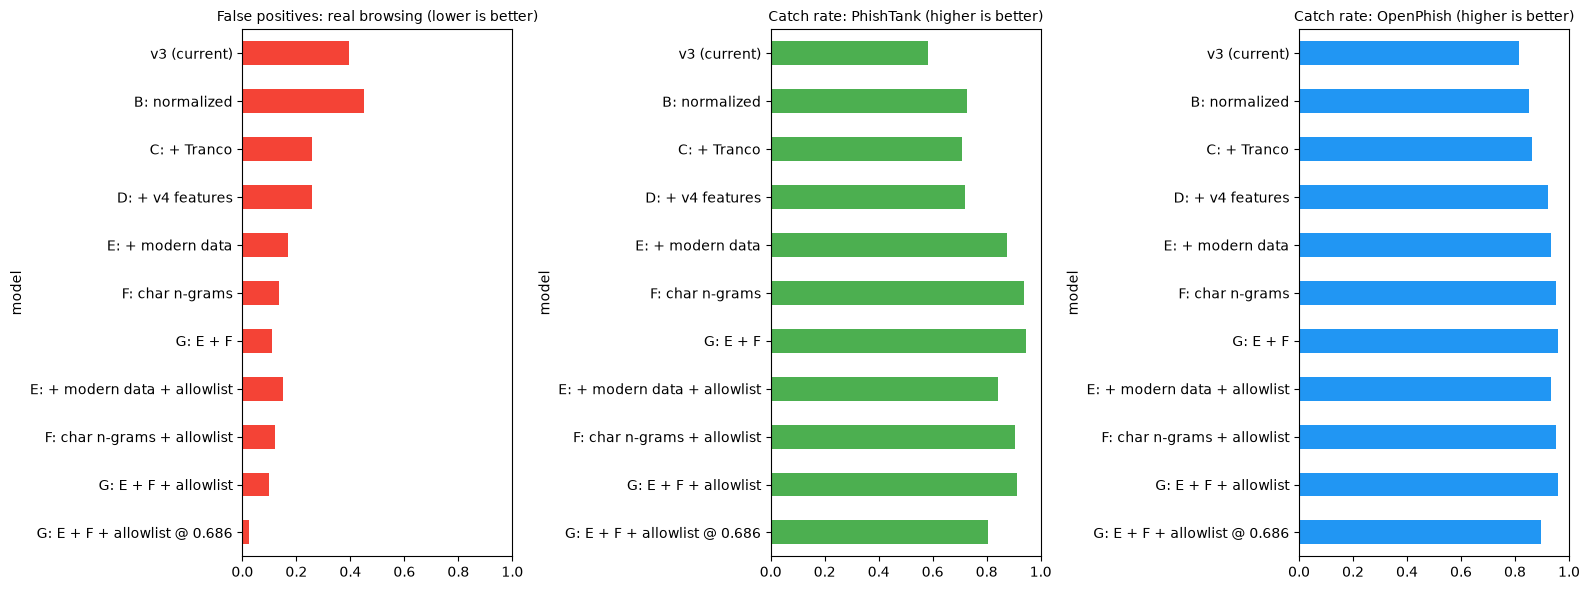

In [15]:
# The headline comparison across all steps at the default 0.5, plus the chosen operating point
summary = pd.concat([comparison, operating.loc[[operating['catch_score'].idxmax()]].drop(
    columns=['candidate', 'threshold', 'catch_score'])])

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, col, title, color in [(axes[0], 'browsing_fpr', 'False positives: real browsing (lower is better)', '#F44336'),
                              (axes[1], 'phishtank_tpr', 'Catch rate: PhishTank (higher is better)', '#4CAF50'),
                              (axes[2], 'openphish_tpr', 'Catch rate: OpenPhish (higher is better)', '#2196F3')]:
    summary[col].plot(kind='barh', ax=ax, color=color)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
# Spot checks, including the README demo URLs
chosen_proba = candidates[CHOSEN]
spot_checks = [
    'https://www.wikipedia.org/',
    'https://www.bbc.co.uk/news/technology',
    'https://github.com/scikit-learn/scikit-learn/issues',
    'https://smallbakery.net/recipes/sourdough-starter',
    'https://blog.janedoe.dev/2026/03/notes-on-rust-lifetimes',
    'http://example.com/login/secure/account/update/verify/admin/nested/dir1/dir2/dir3/session/auth?token=928371982739182371&redirect=%20%20%20',
    'http://paypal.com.secure-login-verify.xyz/account/update/signin.php?session=8f3a9c2e71',
    'http://paypal.com.account-verify.xyz/login',
    'https://sites.google.com/view/paypal-account-recovery/login',
    'http://192.168.13.7:8080/bins/mirai.arm',
]
for url, p in zip(spot_checks, chosen_proba(spot_checks)):
    if allowlist_module.is_allowlisted(url, allow_set):
        print(f"   -    Safe (allowlisted)  {url[:90]}")
    else:
        print(f"{p:6.3f}  {'Malicious' if p > THRESHOLD else 'Safe':9}            {url[:90]}")

   -    Safe (allowlisted)  https://www.wikipedia.org/
   -    Safe (allowlisted)  https://www.bbc.co.uk/news/technology
   -    Safe (allowlisted)  https://github.com/scikit-learn/scikit-learn/issues
 0.390  Safe                 https://smallbakery.net/recipes/sourdough-starter
 0.049  Safe                 https://blog.janedoe.dev/2026/03/notes-on-rust-lifetimes
   -    Safe (allowlisted)  http://example.com/login/secure/account/update/verify/admin/nested/dir1/dir2/dir3/session/
 0.734  Malicious            http://paypal.com.secure-login-verify.xyz/account/update/signin.php?session=8f3a9c2e71
 0.914  Malicious            http://paypal.com.account-verify.xyz/login
 0.435  Safe                 https://sites.google.com/view/paypal-account-recovery/login
 1.000  Malicious            http://192.168.13.7:8080/bins/mirai.arm


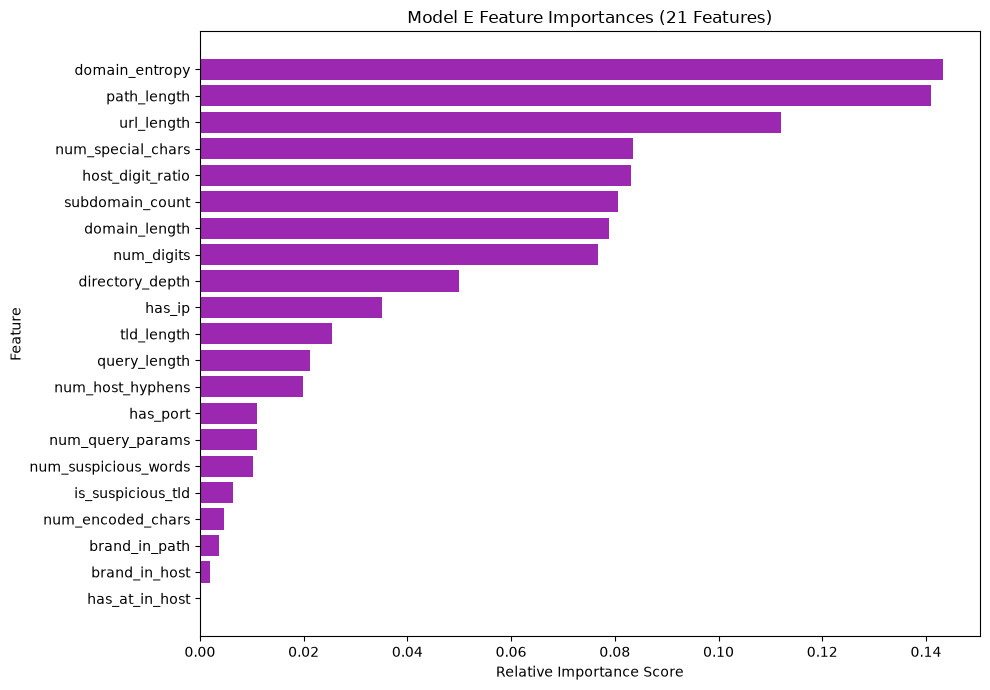

Most malicious n-grams: ['.exe', '.de/', '.ex', 'exe', '.ml', '.gq', '.cf', '.jpg', 'jpg', '.com/', 'om/', 'com/', '.ga', 'cs.', '.top', '.edu/', '00.', '.we', 'du/', 'edu/', 'jp/', '.jp/', 'web', 'org/', '000.', 'de.go', '.000.', '.org/', 'rg/', 'com-']
Most benign n-grams:    ['.ai', '.io', '.dev', 'blog/', '.0000', 'ai-', 'film', 'log/', '/p/', 'an-', 'ook.c', 'og/', '/00', '.app', '/00.0', '.edu', 'ng-', 'wn.co', '/payp', '.de', '-ai', 'wn.c', 'blog', '.md', 'llm', '.org', 'ing-', '-la', 'osts/', '.tv']


In [17]:
importance_df = pd.DataFrame({'Feature': FEATURE_COLUMNS, 'Importance': model_e.feature_importances_})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 7))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='#9C27B0')
plt.gca().invert_yaxis()
plt.title('Model E Feature Importances (21 Features)')
plt.xlabel('Relative Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# The n-grams pushing hardest toward each class in model F - a quick check for new leaks
coefs = model_f.coef_[0]
names = np.array(vectorizer.get_feature_names_out())
order = np.argsort(coefs)
print("Most malicious n-grams:", list(names[order[-30:]][::-1]))
print("Most benign n-grams:   ", list(names[order[:30]]))

## Step 7: Save

The bundle carries everything the API needs to reproduce the chosen scoring exactly: the model(s),
feature order, vectorizer and threshold. The allowlist ships separately as `allowlist.txt`.

In [18]:
uses_rf = CHOSEN in ('E: + modern data', 'G: E + F')
uses_text = CHOSEN in ('F: char n-grams', 'G: E + F')
bundle = {
    'version': 'v4',
    'kind': {'E: + modern data': 'rf', 'F: char n-grams': 'char_lr', 'G: E + F': 'ensemble'}[CHOSEN],
    'rf_model': model_e if uses_rf else None,
    'feature_columns': FEATURE_COLUMNS,
    'text_model': model_f if uses_text else None,
    'vectorizer': vectorizer if uses_text else None,
    'threshold': THRESHOLD,
    'trained_at': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
}
# compress=3 shrinks the file several-fold with identical predictions
joblib.dump(bundle, os.path.join(OUTPUT_DIR, 'url_classifier_v4.joblib'), compress=3)
print(f"Saved {bundle['kind']} bundle (threshold {THRESHOLD:.3f}) to url_classifier_v4.joblib")

# Held-out results of the chosen operating point, read by retrain.py's quality gates
chosen_row = operating.loc[operating['candidate'] == CHOSEN].iloc[0]
metrics_out = {
    'trained_at': bundle['trained_at'],
    'model': CHOSEN,
    'kind': bundle['kind'],
    'threshold': THRESHOLD,
    **{k: float(chosen_row[k]) for k in ['browsing_fpr', 'hn_fpr', 'homepage_fpr', 'phishtank_tpr',
                                          'openphish_tpr', 'urlhaus_tpr', 'test_tpr', 'test_fpr']},
    'eval_sizes': {name: len(urls) for name, urls in EVAL_SETS.items()},
}
with open(os.path.join(OUTPUT_DIR, 'metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(metrics_out, f, indent=2)
print(json.dumps(metrics_out, indent=2))

Saved ensemble bundle (threshold 0.686) to url_classifier_v4.joblib
